# Annex — Which opening families behave alike?
## Complement to C2_clustering.ipynb, same route (clustering)

**Group 03:** Javier Alcaíno, Lucas Riquelme and Renato Varela.

This notebook is an **optional annex** that complements `C2_clustering.ipynb`, not a second
certamen or a second route. `C2_clustering.ipynb` grouped **games** (player-game
perspective) and found that the groups end up dominated by speed and rating, adding little
about specific openings — something already discussed when reviewing those results:
grouping games is not the most direct way to answer "which openings behave alike, so they
can be grouped into the same study material?".

This annex changes the **unit of analysis**: instead of one row per game, **one row is one
opening family** (from those observed in `opening_family_20`), described by how it behaves
in the games where it appears. This is still clustering — we are just grouping openings,
not players.


## 1. Why this is closer to what the coordinator actually needs

The coordinator does not decide "which group does this game fall into" — they decide
**which openings to group into the same review material**. Grouping openings directly by
their observed behaviour (not by their name or tactical family) answers that question much
more directly.

**A warning that applies even more strongly here than in the main notebook:** if two
openings land in the same group because they show a similar score pattern, that **does
not** mean those openings are "equally good," nor that one is better than the other. The
pool of players who choose each opening is not random — players of a certain level or style
tend to prefer certain openings. If an opening appears in a lower-scoring group, that is a
**signal of where to look more closely** (review those specific games), not a conclusion
about whether that opening "works." The observed difference could be entirely explained by
who plays it, not by the opening itself — exactly the same underlying problem that prevents
any causal claim throughout this whole project.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

def find_root():
    here = Path.cwd().resolve()
    candidates = [here, *here.parents, here / "GROUP_03_Chess"]
    return next(p for p in candidates if (p / "provenance/source_manifest.json").exists())

ROOT = find_root()
TABLES = ROOT / "outputs/tables"
FIGURES = ROOT / "outputs/figures"
contract = json.loads((ROOT / "provenance/W2_frozen_contract.json").read_text())
SEED = contract["seed"]
MIN_OPENING_GAMES = 100  # minimum July games for an opening's profile to be trustworthy

pd.set_option("display.max_columns", 15)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "axes.spines.top": False,
                     "axes.spines.right": False, "font.family": "DejaVu Sans"})

def save_figure(name):
    plt.savefig(FIGURES / name, bbox_inches="tight", facecolor="white")
    plt.show()

train = pd.read_csv(ROOT / "data/splits/train.csv")
validation = pd.read_csv(ROOT / "data/splits/validation.csv")
test = pd.read_csv(ROOT / "data/splits/test.csv")
print(f"Loaded train (July)={len(train):,}, validation (August)={len(validation):,}, "
      f"test (September)={len(test):,} games. Minimum games per opening: {MIN_OPENING_GAMES}.")


Loaded train (July)=30,615, validation (August)=25,782, test (September)=30,553 games. Minimum games per opening: 100.


## 2. Building each opening's profile (July only)

Each opening is described by 5 numbers, all computed **using July only** (the same
fit-only-on-training discipline used throughout the rest of the project):

- `score_rate_white`: white's score rate in games with that opening (we do **not** pool it
  with black -- unlike the main notebook, there is no "both colours in the same row"
  artefact here, because each opening is a single row, and black's score is simply the
  exact mathematical complement of 1 minus white's).
- `draw_rate`: share of draws.
- `mean_rating`: average rating of the players who play it (the typical skill level
  associated with the opening).
- `pct_blitz`: share of blitz vs. rapid games.
- `rating_score_corr`: correlation between white's rating and white's score, within that
  opening (does it favour stronger players more, or give even results regardless of level?).

We only include openings with at least `MIN_OPENING_GAMES` games in July, so these numbers
are not pure statistical noise.


In [2]:
def opening_profile(games):
    white_score = games.outcome.map({"white_win": 1.0, "draw": 0.5, "black_win": 0.0})
    g = games.assign(white_score=white_score).groupby("opening_family_20", observed=True)

    def _agg(sub):
        n = len(sub)
        out = {
            "n_games": n,
            "score_rate_white": sub.white_score.mean(),
            "draw_rate": (sub.outcome == "draw").mean(),
            "mean_rating": sub.white_rating.mean(),
            "pct_blitz": (sub.speed == "blitz").mean(),
        }
        out["rating_score_corr"] = (sub.white_rating.corr(sub.white_score)
                                     if n >= 30 and sub.white_rating.std() > 0 else np.nan)
        return pd.Series(out)

    return g.apply(_agg, include_groups=False).reset_index()

FEATURES = ["score_rate_white", "draw_rate", "mean_rating", "pct_blitz", "rating_score_corr"]

profile_jul = opening_profile(train)
profile_jul_fit = profile_jul[profile_jul.n_games >= MIN_OPENING_GAMES].reset_index(drop=True)
print(f"{len(profile_jul_fit)} of {len(profile_jul)} opening families in July reach "
      f">= {MIN_OPENING_GAMES} games (covering "
      f"{profile_jul_fit.n_games.sum() / profile_jul.n_games.sum():.1%} of July games).")
print(profile_jul_fit.sort_values("n_games", ascending=False).head(8).round(3).to_string(index=False))


46 of 137 opening families in July reach >= 100 games (covering 92.8% of July games).
   opening_family_20   n_games  score_rate_white  draw_rate  mean_rating  pct_blitz  rating_score_corr
    Sicilian Defense 3,267.000             0.496      0.039    1,699.750      0.775              0.063
   Queen's Pawn Game 3,113.000             0.519      0.042    1,524.072      0.758              0.015
      French Defense 1,888.000             0.507      0.043    1,626.151      0.789              0.001
   Caro-Kann Defense 1,816.000             0.505      0.041    1,609.907      0.741              0.031
Scandinavian Defense 1,501.000             0.473      0.051    1,515.650      0.747             -0.014
        Italian Game 1,491.000             0.526      0.048    1,477.313      0.657              0.015
    King's Pawn Game   955.000             0.519      0.038    1,328.351      0.672              0.029
     English Opening   927.000             0.539      0.054    1,706.804      0.780       

## 3. Representation: standardise and reduce with PCA

We follow the same sequence taught in the course's clustering practice:
`X → PCA → model → profile`. With only 5 variables this is not strictly necessary for
memory or compute reasons (unlike the main notebook, there are no 140 categories here), but
it is still useful to visualise in 2D and confirm the variables are not redundant with each
other. The scaler and PCA are fit **using July's openings only**.


In [3]:
scaler = StandardScaler().fit(profile_jul_fit[FEATURES])
X_jul = scaler.transform(profile_jul_fit[FEATURES])
pca = PCA(n_components=3, random_state=SEED).fit(X_jul)
Xp_jul = pca.transform(X_jul)
print("Explained variance per component:", pca.explained_variance_ratio_.round(3))
print("Cumulative explained variance:", pca.explained_variance_ratio_.cumsum().round(3))
print("Loadings of the first 2 components:")
print(pd.DataFrame(pca.components_[:2].T, index=FEATURES, columns=["PC1", "PC2"]).round(3))


Explained variance per component: [0.357 0.247 0.207]
Cumulative explained variance: [0.357 0.604 0.812]
Loadings of the first 2 components:
                     PC1    PC2
score_rate_white  -0.204  0.592
draw_rate         -0.098  0.742
mean_rating        0.677  0.214
pct_blitz          0.699  0.060
rating_score_corr -0.030 -0.222


## 4. Choosing K with a Gaussian Mixture Model (GMM)

The main notebook used k-prototypes (mixed-type data). Here, with numeric-only variables,
we use a **Gaussian Mixture Model (GMM)** — the same alternative to K-means the
unsupervised-models class presents for when group membership can be uncertain or
overlapping. We choose K with the **BIC** (Bayesian Information Criterion, as taught in
class): smaller values are preferred, subject to group sizes remaining interpretable.


 K     BIC  silhouette                sizes
 2 477.878       0.253             [16, 30]
 3 493.029       0.223          [7, 24, 15]
 4 518.412       0.239      [15, 10, 16, 5]
 5 516.250       0.192   [11, 14, 12, 8, 1]
 6 523.149       0.280 [3, 14, 6, 1, 9, 13]


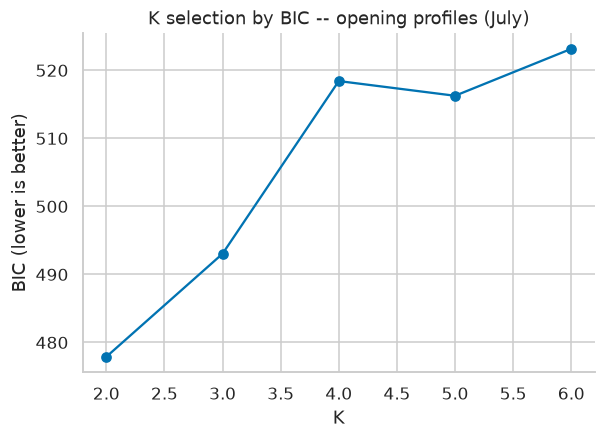


Chosen K = 2 (lowest BIC). Groups with a single member at larger K (e.g. K=6) are not evidence of better structure -- they are overfitting with few data points (only 46 openings in total).


In [4]:
bic_rows = []
for k in range(2, 7):
    gm_k = GaussianMixture(n_components=k, random_state=SEED, n_init=10).fit(Xp_jul)
    labels_k = gm_k.predict(Xp_jul)
    sizes = pd.Series(labels_k).value_counts().sort_index().tolist()
    sil = silhouette_score(Xp_jul, labels_k) if len(set(labels_k)) > 1 else np.nan
    bic_rows.append({"K": k, "BIC": gm_k.bic(Xp_jul), "silhouette": sil, "sizes": sizes})

bic_table = pd.DataFrame(bic_rows)
bic_table.to_csv(TABLES / "C2_anexo_bic_selection.csv", index=False)
print(bic_table.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(bic_table.K, bic_table.BIC, "o-")
ax.set_xlabel("K"); ax.set_ylabel("BIC (lower is better)")
ax.set_title("K selection by BIC -- opening profiles (July)")
save_figure("C2_anexo_01_bic.png")

K_CHOSEN = int(bic_table.loc[bic_table.BIC.idxmin(), "K"])
print(f"\nChosen K = {K_CHOSEN} (lowest BIC). Groups with a single member at larger K "
      f"(e.g. K=6) are not evidence of better structure -- they are overfitting with few "
      f"data points (only {len(profile_jul_fit)} openings in total).")


## 5. Opening-group profiles (July)

**Records used:** the 46 opening families with at least 100 games in July. **Variables
used:** the 5 described in Section 2. Conclusions are limited to these families -- low-
frequency openings are excluded for lack of sufficient evidence, not because they are
assumed not to matter.


         score_rate_white  draw_rate  mean_rating  pct_blitz  rating_score_corr  n_games  n_openings
cluster                                                                                             
0                   0.533      0.048    1,453.539      0.691              0.025  652.688          16
1                   0.506      0.043    1,631.972      0.778              0.017  598.567          30

Group 0 (16 openings): Bishop's Opening, Center Game, Four Knights Game, Italian Game, King's Knight Opening, King's Pawn Game, Nimzowitsch Defense, Petrov's Defense, Ponziani Opening, Queen's Gambit Accepted, Queen's Pawn Game, Ruy Lopez, Scotch Game, Three Knights Opening, Van't Kruijs Opening, Vienna Game
Group 1 (30 openings): Alekhine Defense, Benoni Defense, Bird Opening, Caro-Kann Defense, Dutch Defense, English Defense, English Opening, Englund Gambit, Englund Gambit Declined, French Defense, Horwitz Defense, Hungarian Opening, Indian Defense, King's Gambit Accepted, King's Gambit

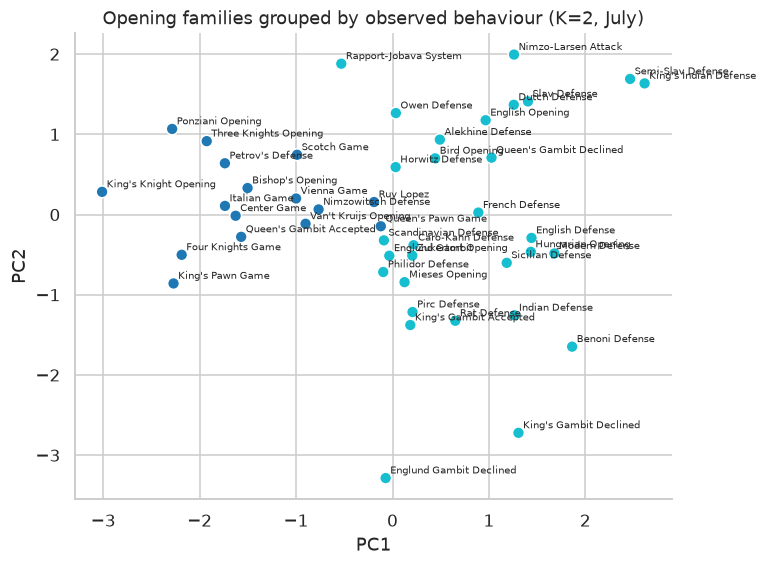

In [5]:
gm = GaussianMixture(n_components=K_CHOSEN, random_state=SEED, n_init=10).fit(Xp_jul)
profile_jul_fit = profile_jul_fit.assign(cluster=gm.predict(Xp_jul))

cluster_summary = profile_jul_fit.groupby("cluster")[FEATURES + ["n_games"]].mean().round(3)
cluster_summary["n_openings"] = profile_jul_fit.groupby("cluster").size()
print(cluster_summary.to_string())
print()

for c in sorted(profile_jul_fit.cluster.unique()):
    names = profile_jul_fit.loc[profile_jul_fit.cluster == c, "opening_family_20"].tolist()
    print(f"Group {c} ({len(names)} openings): {', '.join(sorted(names))}")

profile_jul_fit.to_csv(TABLES / "C2_anexo_opening_clusters_july.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 5.5))
scatter = ax.scatter(Xp_jul[:, 0], Xp_jul[:, 1], c=profile_jul_fit.cluster, cmap="tab10",
                      s=60, edgecolor="white")
for i, row in profile_jul_fit.iterrows():
    ax.annotate(row.opening_family_20, (Xp_jul[i, 0], Xp_jul[i, 1]), fontsize=6.5,
                xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title(f"Opening families grouped by observed behaviour (K={K_CHOSEN}, July)")
save_figure("C2_anexo_02_opening_clusters.png")


## 6. Comparison with the simple rule already used in C1

C1 already built a "training agenda" (`C1_training_agenda.csv`) using a deliberately simple
rule: pick the **most frequent** opening within each colour×speed×level cell, with no model
involved. We check whether grouping by behaviour (this annex) distinguishes something that
the frequency rule, on its own, does not.


In [6]:
freq_rank = profile_jul_fit.sort_values("n_games", ascending=False).reset_index(drop=True)
top_by_frequency = freq_rank.head(K_CHOSEN + 2)[["opening_family_20", "n_games", "cluster"]]
print("Most frequent openings in July (C1's simple rule) and which behaviour group they "
      "belong to:")
print(top_by_frequency.to_string(index=False))

n_clusters_among_top = top_by_frequency.cluster.nunique()
print(f"\nThe {len(top_by_frequency)} most frequent openings fall into {n_clusters_among_top} "
      f"distinct behaviour group(s) (out of {K_CHOSEN} possible). "
      + ("This suggests the frequency rule on its own mixes openings with different "
         "profiles into the same review package -- grouping by behaviour does add "
         "something frequency alone does not see." if n_clusters_among_top > 1 else
         "In this case the most frequent openings turned out fairly similar in "
         "behaviour, so the simple rule would already have treated them alike."))


Most frequent openings in July (C1's simple rule) and which behaviour group they belong to:
opening_family_20   n_games  cluster
 Sicilian Defense 3,267.000        1
Queen's Pawn Game 3,113.000        0
   French Defense 1,888.000        1
Caro-Kann Defense 1,816.000        1

The 4 most frequent openings fall into 2 distinct behaviour group(s) (out of 2 possible). This suggests the frequency rule on its own mixes openings with different profiles into the same review package -- grouping by behaviour does add something frequency alone does not see.


## 7. Sensitivity to the month: do the groups hold in August and September?

As in the main notebook, we recompute each opening's profile using August and September
separately (not just July), and assign each opening to its nearest group using the
**same** scaler and PCA fit on July (no refitting). If an opening changes group between
months, its observed behaviour is not stable and should be read with more caution.


In [7]:
def assign_other_month(games, month_label):
    prof = opening_profile(games)
    prof = prof[prof.opening_family_20.isin(profile_jul_fit.opening_family_20)].reset_index(drop=True)
    X = scaler.transform(prof[FEATURES].fillna(profile_jul_fit[FEATURES].mean()))
    Xp = pca.transform(X)
    prof[f"cluster_{month_label}"] = gm.predict(Xp)
    return prof[["opening_family_20", "n_games", f"cluster_{month_label}"]].rename(
        columns={"n_games": f"n_games_{month_label}"})

aug_assign = assign_other_month(validation, "aug")
sep_assign = assign_other_month(test, "sep")

stability = profile_jul_fit[["opening_family_20", "cluster", "n_games"]].rename(
    columns={"cluster": "cluster_jul", "n_games": "n_games_jul"})
stability = stability.merge(aug_assign, on="opening_family_20", how="left")
stability = stability.merge(sep_assign, on="opening_family_20", how="left")
stability["stable_jul_aug"] = stability.cluster_jul == stability.cluster_aug
stability["stable_jul_sep"] = stability.cluster_jul == stability.cluster_sep
stability.to_csv(TABLES / "C2_anexo_month_stability.csv", index=False)

print(f"Openings whose group stays the same between July and August: "
      f"{stability.stable_jul_aug.mean():.1%} ({stability.stable_jul_aug.sum()}/{len(stability)})")
print(f"Openings whose group stays the same between July and September: "
      f"{stability.stable_jul_sep.mean():.1%} ({stability.stable_jul_sep.sum()}/{len(stability)})")
print()
print("Openings that DID change group in some month (review with more caution):")
changed = stability[~(stability.stable_jul_aug & stability.stable_jul_sep)]
print(changed[["opening_family_20", "cluster_jul", "cluster_aug", "cluster_sep"]].to_string(index=False))


Openings whose group stays the same between July and August: 87.0% (40/46)
Openings whose group stays the same between July and September: 87.0% (40/46)

Openings that DID change group in some month (review with more caution):
      opening_family_20  cluster_jul  cluster_aug  cluster_sep
            Center Game            0            1            0
  King's Knight Opening            0            1            0
    Nimzowitsch Defense            0            1            1
       Philidor Defense            1            0            0
           Pirc Defense            1            0            1
Queen's Gambit Accepted            0            0            1
  Rapport-Jobava System            1            1            0
   Scandinavian Defense            1            1            0
   Van't Kruijs Opening            0            1            1


## 8. Interpretation and causal caveat (again, with more emphasis)

### What we found

Of the 137 opening families observed in July, 46 have enough evidence (≥100 games) to
build a reliable profile, covering 92.8% of July's games. The BIC clearly prefers **K=2**
(477.9, the lowest value; K=3 already rises to 493.0) -- larger K values produce
single-opening groups (K=5, K=6), which is not evidence of real structure but overfitting
with only 46 data points.

The two groups found are interpretable and distinct:

- **Group 0 (16 openings):** lower average rating (≈1,454), somewhat higher white score
  rate (53.3%), relatively more rapid-leaning (69.1% blitz, vs. 77.8% in Group 1). Includes
  Ruy Lopez, Italian Game, King's Pawn Game, Queen's Pawn Game, Scotch Game, Four Knights
  Game -- classical openings, often among the first a player learns.
- **Group 1 (30 openings):** higher average rating (≈1,632), white score rate closer to
  even (50.6%), more blitz-leaning (77.8%). Includes Sicilian Defense, French Defense,
  Caro-Kann, Slav Defense, Semi-Slav Defense, King's Indian Defense -- sharper or more
  theoretical openings, typically associated with more-prepared players.

### This does add something the simple C1 rule did not see

The 4 most frequent openings in July (Sicilian Defense, Queen's Pawn Game, French Defense,
Caro-Kann Defense -- the same frequency rule C1 used for its training agenda) **do not all
fall into the same behaviour group**: Queen's Pawn Game lands in Group 0, the other three in
Group 1. In other words, choosing review material by frequency alone (as C1 did) would mix,
within the same package, openings with different player profiles and different outcome
patterns. Grouping by behaviour does distinguish something frequency alone does not -- this
is the concrete improvement we were looking for relative to the main notebook.

### Sensitivity to the month

87.0% of openings (40 of 46) keep the same group between July and August, and also 87.0%
between July and September. The 9 openings that change group in some month (e.g. Center
Game, King's Knight Opening, Philidor Defense, Scandinavian Defense) tend to be the
lower-volume ones within the 100-game threshold -- that is, they sit right at the boundary
between the two profiles, and their classification is more sensitive to the specific month
observed. We recommend treating those 9 with more caution than the remaining 37, whose
classification did stay stable across all three months.

### The causal caveat, again, with more force

This is exactly what was discussed before building this annex, and it is worth stating
explicitly: **Group 0 does not "score more because it is a superior opening."** It is
reasonable to think Group 0 bundles simpler openings that less experienced players tend to
choose, and Group 1 bundles more theory-heavy openings that more dedicated players tend to
prepare -- the correlation between `mean_rating` and group membership (visible in the PC1
loadings: 0.677 for `mean_rating`, 0.699 for `pct_blitz`) is precisely the clue that player
level, not the opening itself, could explain much of the score difference between groups.
No player was randomly assigned to an opening; each one chooses it according to their own
level and preparation. A group of openings with a certain result pattern is a **flag for
where to look more closely**, not a conclusion about whether that opening "works" -- see
also Section 8 of `C2_clustering.ipynb`, where the exact same reasoning is applied to
colour.


## AI-use note and references

This annex was designed and implemented with support from Claude Code (Anthropic) --
variable selection, profiling/PCA/GMM code, and drafting of the interpretation -- under the
team's direct supervision; every number comes from this notebook's actual execution.

**Additional references, beyond those already cited in `C2_clustering.ipynb`:**

1. Schwarz, G. (1978). *Estimating the Dimension of a Model* (the BIC criterion).
2. Course material: `06_.../BI_Trimestral_Unsupervised_Models_Masterclass.ipynb`, the
   Gaussian Mixture Models and BIC-based component selection section.
3. `outputs/tables/C1_training_agenda.csv` -- C1's frequency rule, used as the simple
   reference in Section 6.
